# EDA: Downtown San Diego Homeless Population Analysis
**Task 2.1 — Summary Statistics & Temporal Patterns**

Source: `data/MasterCounts_Adjusted_v2.csv` (canonical adjusted counts, Task 1.3 deliverable)

This notebook covers:
1. Data load & scoping
2. Summary statistics (overall & by neighborhood)
3. Monthly seasonality
4. Year-over-year % change (overall & by neighborhood)
5. Top 3 neighborhoods by average count and by growth rate


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

MONTH_ORDER = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']


## 1. Load Data & Scope

The canonical dataset is stored **long-format**: each area-month can have up to 4 rows
(`component` = `total`, `individual`, `vehicle`, `tent`). For headline population analysis
we use `component == 'total'` to avoid double-counting.

`area_type` distinguishes 7 top-level **neighborhoods** (incl. `East Village` as a parent)
from 4 **East Village sub-areas** (`North East EV`, `North West EV`, `South East EV`, `South West EV`).
Primary analysis uses `area_type == 'neighborhood'`; sub-areas are examined separately where relevant.


In [2]:
df = pd.read_csv('data/MasterCounts_Adjusted_v2.csv', parse_dates=['date'])
print(f"Rows: {len(df):,}  |  Date range: {df['date'].min().date()} to {df['date'].max().date()}")
df.head()


Rows: 2,814  |  Date range: 2017-01-01 to 2025-12-01


,date,year,month,area,source_area,component,area_type,method,raw_count,total_count
0,2021-01-01,2021,Jan,East Village,East Village,total,neighborhood,POST2020,409.0,409.12
1,2021-01-01,2021,Jan,City Center,City Center,total,neighborhood,POST2020,153.0,153.03
2,2021-01-01,2021,Jan,Columbia,Columbia,total,neighborhood,POST2020,55.0,54.50
3,2021-01-01,2021,Jan,Marina,Marina,total,neighborhood,POST2020,20.0,20.00
4,2021-01-01,2021,Jan,Cortez,Cortez,total,neighborhood,POST2020,47.0,47.00


In [3]:
# Scope to headline totals, neighborhood-level areas
totals = df[(df['component'] == 'total') & (df['area_type'] == 'neighborhood')].copy()
totals['month'] = pd.Categorical(totals['month'], categories=MONTH_ORDER, ordered=True)

print(f"Neighborhood-level total rows: {len(totals):,}")
print(f"Neighborhoods ({totals['area'].nunique()}): {sorted(totals['area'].unique())}")
print(f"Nulls in total_count: {totals['total_count'].isna().sum()}")
totals[['date','year','month','area','total_count']].head()


Neighborhood-level total rows: 708
Neighborhoods (7): ['City Center', 'Columbia', 'Cortez', 'East Village', 'Gaslamp', 'Marina', 'Outside Perimeter']
Nulls in total_count: 28


,date,year,month,area,total_count
0,2021-01-01,2021,Jan,East Village,409.12
1,2021-01-01,2021,Jan,City Center,153.03
2,2021-01-01,2021,Jan,Columbia,54.50
3,2021-01-01,2021,Jan,Marina,20.00
4,2021-01-01,2021,Jan,Cortez,47.00


## 2. Summary Statistics

Mean, median, min, max, and standard deviation of monthly counts — overall and by neighborhood.


In [4]:
overall_stats = totals['total_count'].agg(['mean','median','min','max','std']).round(2)
print("Overall monthly count statistics (all neighborhoods, all months):")
overall_stats


Overall monthly count statistics (all neighborhoods, all months):


mean      156.78
median     58.88
min         0.00
max       921.05
std       197.38
Name: total_count, dtype: float64

In [5]:
by_neighborhood_stats = (
    totals.groupby('area')['total_count']
    .agg(['mean','median','min','max','std','count'])
    .round(2)
    .sort_values('mean', ascending=False)
)
print("Summary statistics by neighborhood (sorted by mean):")
by_neighborhood_stats


Summary statistics by neighborhood (sorted by mean):


,mean,median,min,max,std,count
area,,,,,,
East Village,552.77,504.85,260.59,921.05,157.09,104
Outside Perimeter,217.57,185.50,0.00,640.00,177.92,56
City Center,171.81,156.67,91.00,342.31,54.80,104
Cortez,59.52,51.88,16.00,170.46,30.22,104
Gaslamp,48.43,46.12,18.50,93.00,14.00,104
Columbia,44.49,45.12,13.75,84.50,13.72,104
Marina,30.94,27.38,4.06,79.00,15.82,104


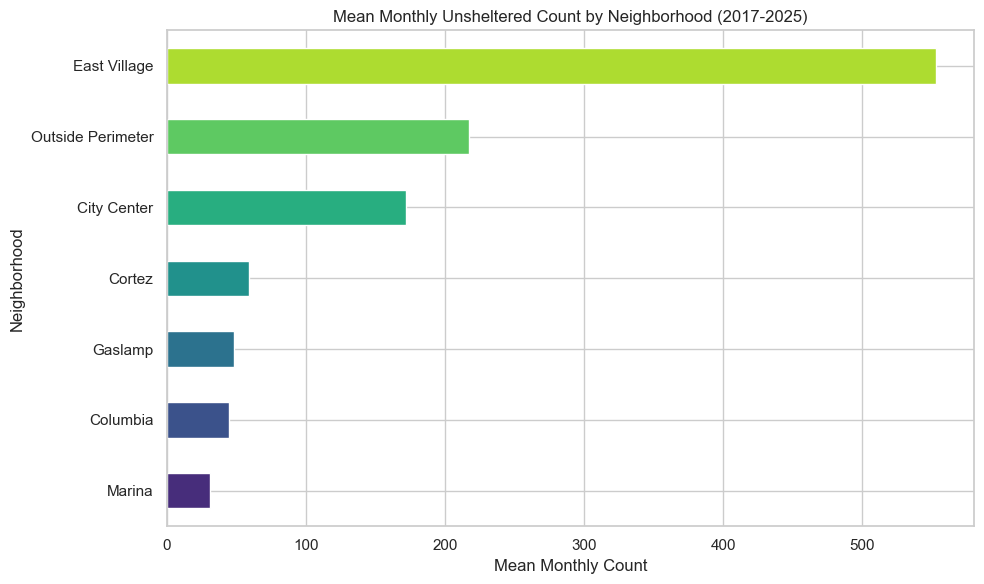

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
by_neighborhood_stats['mean'].sort_values().plot(kind='barh', ax=ax, color=sns.color_palette('viridis', len(by_neighborhood_stats)))
ax.set_xlabel('Mean Monthly Count')
ax.set_ylabel('Neighborhood')
ax.set_title('Mean Monthly Unsheltered Count by Neighborhood (2017-2025)')
plt.tight_layout()
plt.show()


## 3. Monthly Seasonality

Average count by calendar month across all years — overall and by neighborhood — to identify
consistently high and low months.


In [7]:
seasonality_overall = (
    totals.groupby('month', observed=True)['total_count']
    .agg(['mean','std','count'])
    .round(2)
    .reindex(MONTH_ORDER)
)
print("Overall seasonality (avg count by calendar month, across all years):")
seasonality_overall


Overall seasonality (avg count by calendar month, across all years):


,mean,std,count
month,,,
Jan,157.68,199.00,59
Feb,161.76,195.43,59
Mar,148.67,187.34,59
Apr,153.53,189.95,59
May,160.93,197.06,59
Jun,159.30,198.93,59
Jul,160.48,211.42,52
Aug,161.61,216.38,52
Sep,153.63,207.85,59


In [8]:
high_months = seasonality_overall['mean'].nlargest(3)
low_months = seasonality_overall['mean'].nsmallest(3)
print("Top 3 highest-count months (overall):")
print(high_months)
print("\nTop 3 lowest-count months (overall):")
print(low_months)


Top 3 highest-count months (overall):
month
Feb    161.76
Aug    161.61
May    160.93
Name: mean, dtype: float64

Top 3 lowest-count months (overall):
month
Mar    148.67
Nov    153.43
Apr    153.53
Name: mean, dtype: float64


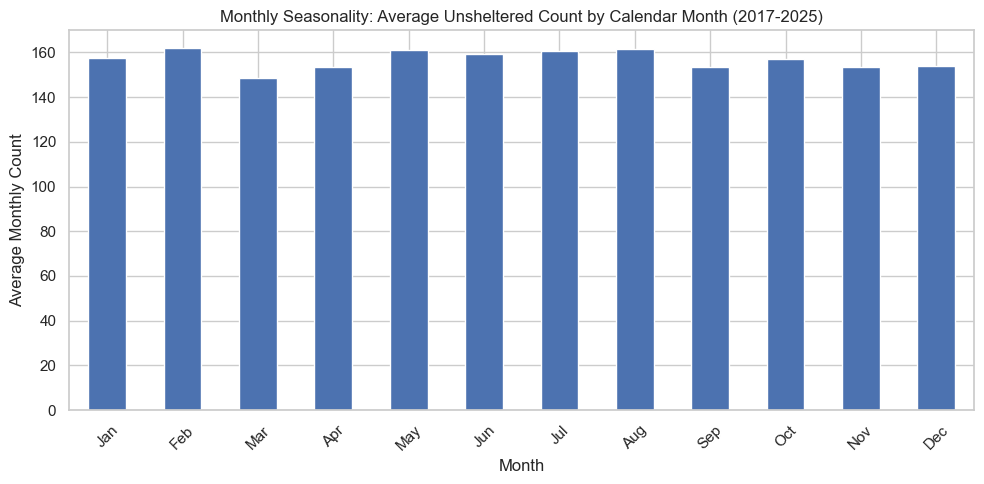

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
seasonality_overall['mean'].plot(kind='bar', ax=ax, color='#4C72B0')
ax.set_ylabel('Average Monthly Count')
ax.set_xlabel('Month')
ax.set_title('Monthly Seasonality: Average Unsheltered Count by Calendar Month (2017-2025)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [10]:
seasonality_by_neighborhood = (
    totals.pivot_table(index='area', columns='month', values='total_count', aggfunc='mean', observed=True)
    .reindex(columns=MONTH_ORDER)
    .round(1)
)
print("Seasonality by neighborhood (avg count per calendar month):")
seasonality_by_neighborhood


Seasonality by neighborhood (avg count per calendar month):


month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
area,,,,,,,,,,,,
City Center,167.8,187.9,181.4,168.8,184.8,170.6,164.5,171.7,155.8,177.3,167.3,163.1
Columbia,44.7,47.4,38.4,45.8,47.7,49.7,42.1,48.0,43.1,43.2,42.7,40.9
Cortez,74.2,75.0,51.7,56.4,56.2,52.4,62.7,51.1,57.7,52.9,57.6,64.9
East Village,554.3,546.8,509.4,509.3,530.5,547.6,601.4,603.9,587.9,568.7,533.4,550.9
Gaslamp,47.9,51.1,53.9,42.7,51.0,43.5,39.8,47.1,57.3,50.1,47.4,48.3
Marina,31.4,30.2,28.8,27.5,27.4,32.1,24.8,40.7,33.0,30.6,37.8,28.1
Outside Perimeter,204.0,219.8,199.8,281.0,283.2,267.2,215.8,176.0,130.2,194.2,222.2,205.0


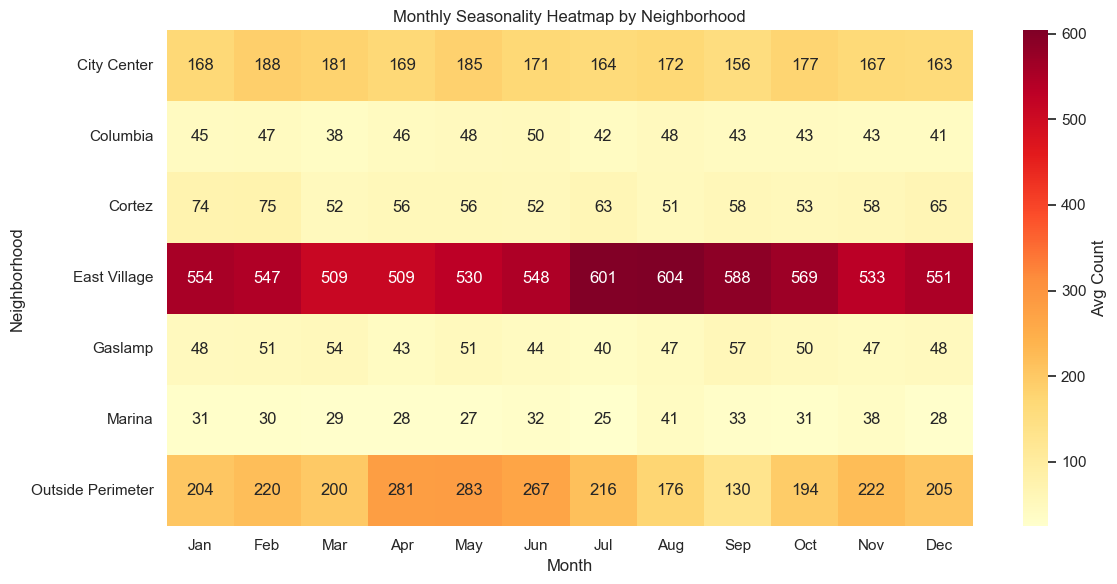

In [11]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(seasonality_by_neighborhood, cmap='YlOrRd', annot=True, fmt='.0f', ax=ax, cbar_kws={'label': 'Avg Count'})
ax.set_title('Monthly Seasonality Heatmap by Neighborhood')
ax.set_xlabel('Month')
ax.set_ylabel('Neighborhood')
plt.tight_layout()
plt.show()


## 4. Year-over-Year % Change

Annual totals (mean monthly count per year, since not every year has 12 reporting months)
and the resulting year-over-year percentage change — overall and by neighborhood.

> **Caveat:** 2017 has only 6 reporting months (72 rows / 12 neighborhoods) and 2025 has
> incomplete/unreleased late-year data (see `docs/DataQualityReport.md`). YoY figures
> touching these edge years should be read with that in mind.


In [12]:
annual_overall = totals.groupby('year')['total_count'].mean().round(2)
yoy_overall = annual_overall.pct_change().mul(100).round(2)

yoy_table = pd.DataFrame({'avg_monthly_count': annual_overall, 'yoy_pct_change': yoy_overall})
print("Overall annual average count & YoY % change:")
yoy_table


Overall annual average count & YoY % change:


,avg_monthly_count,yoy_pct_change
year,,
2017,176.31,NaN
2018,142.84,-18.98
2019,135.79,-4.94
2020,109.02,-19.71
2021,137.20,25.85
2022,216.27,57.63
2023,223.98,3.56
2024,126.50,-43.52
2025,122.78,-2.94


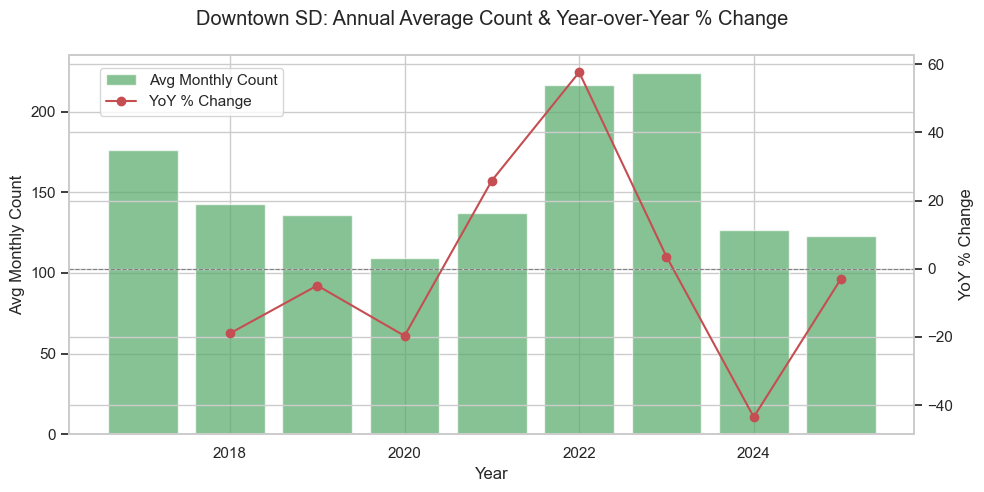

In [13]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(yoy_table.index, yoy_table['avg_monthly_count'], color='#55A868', alpha=0.7, label='Avg Monthly Count')
ax1.set_ylabel('Avg Monthly Count')
ax1.set_xlabel('Year')

ax2 = ax1.twinx()
ax2.plot(yoy_table.index, yoy_table['yoy_pct_change'], color='#C44E52', marker='o', label='YoY % Change')
ax2.set_ylabel('YoY % Change')
ax2.axhline(0, color='gray', linewidth=0.8, linestyle='--')

fig.suptitle('Downtown SD: Annual Average Count & Year-over-Year % Change')
fig.legend(loc='upper left', bbox_to_anchor=(0.1, 0.88))
plt.tight_layout()
plt.show()


In [14]:
annual_by_neighborhood = totals.pivot_table(index='year', columns='area', values='total_count', aggfunc='mean')
yoy_by_neighborhood = annual_by_neighborhood.pct_change().mul(100).round(2)
print("YoY % change by neighborhood (rows=year, cols=neighborhood):")
yoy_by_neighborhood


YoY % change by neighborhood (rows=year, cols=neighborhood):


area,City Center,Columbia,Cortez,East Village,Gaslamp,Marina,Outside Perimeter
year,,,,,,,
2017,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018,-6.10,-5.53,-15.39,-24.88,8.64,-23.94,NaN
2019,-9.15,11.14,-7.07,-5.55,3.10,-8.27,NaN
2020,-7.82,-1.89,-26.60,-22.51,-25.75,-31.85,NaN
2021,16.55,15.57,11.84,25.40,-14.87,4.94,NaN
2022,65.55,-10.92,129.43,50.26,38.86,19.29,87.09
2023,-0.01,-32.69,22.93,10.84,-17.81,-31.10,-1.92
2024,-19.72,7.79,-18.41,-44.09,11.85,-16.42,-80.67
2025,-17.84,-18.96,-28.41,-2.88,-22.75,-25.93,103.08


## 5. Top 3 Neighborhoods

By **average count** (overall magnitude) and by **growth rate** (average YoY % change,
excluding the 2017 stub year and treating 2025 with caution due to incomplete data).


In [15]:
top3_by_avg_count = by_neighborhood_stats['mean'].nlargest(3)
print("Top 3 neighborhoods by average monthly count:")
top3_by_avg_count


Top 3 neighborhoods by average monthly count:


area
East Village         552.77
Outside Perimeter    217.57
City Center          171.81
Name: mean, dtype: float64

In [16]:
# Average YoY growth rate per neighborhood, excluding the 2017->2018 transition
# (2017 is a partial/stub year) for a fairer growth comparison.
growth_rate = yoy_by_neighborhood.loc[2019:].mean().round(2).sort_values(ascending=False)
top3_by_growth = growth_rate.head(3)
print("Average YoY % growth rate by neighborhood (2019 onward):")
print(growth_rate)
print("\nTop 3 neighborhoods by average growth rate:")
top3_by_growth


Average YoY % growth rate by neighborhood (2019 onward):
area
Outside Perimeter    26.90
Cortez               11.96
City Center           3.94
East Village          1.64
Gaslamp              -3.91
Columbia             -4.28
Marina              -12.76
dtype: float64

Top 3 neighborhoods by average growth rate:


area
Outside Perimeter    26.90
Cortez               11.96
City Center           3.94
dtype: float64

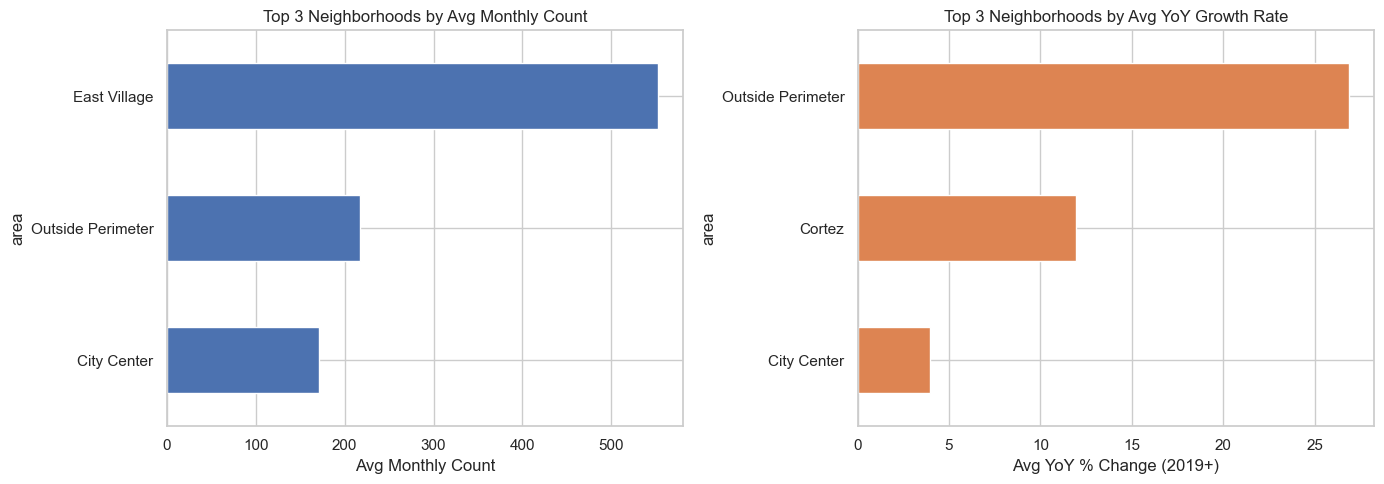

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top3_by_avg_count.sort_values().plot(kind='barh', ax=axes[0], color='#4C72B0')
axes[0].set_title('Top 3 Neighborhoods by Avg Monthly Count')
axes[0].set_xlabel('Avg Monthly Count')

top3_by_growth.sort_values().plot(kind='barh', ax=axes[1], color='#DD8452')
axes[1].set_title('Top 3 Neighborhoods by Avg YoY Growth Rate')
axes[1].set_xlabel('Avg YoY % Change (2019+)')

plt.tight_layout()
plt.show()


## Summary of Findings

- **Overall scale:** Across 2017-2025, neighborhood-level monthly counts (7 neighborhoods, `component == total`) average **156.8** (median 58.9, std 197.4), reflecting a highly skewed distribution driven by East Village.
- **By neighborhood (avg monthly count):** East Village (552.8) >> Outside Perimeter (217.6) > City Center (171.8) > Cortez (59.5) > Gaslamp (48.4) > Columbia (44.5) > Marina (30.9).
- **Seasonality:** Counts are relatively flat month-to-month (range ~149-162 overall), with **Feb (161.8), Aug (161.6), and May (160.9)** running highest and **Mar (148.7), Nov (153.4), and Apr (153.5)** running lowest. East Village itself peaks in **Jul-Aug** (601-604) and dips in spring (Mar-Apr, ~509).
- **YoY trend:** Overall average count fell steadily 2018-2020 (COVID-era lows, -19.7% in 2020), rebounded sharply in 2021-2022 (+25.9%, +57.6%, peaking at 224 in 2023), then dropped again in 2024 (-43.5%) before roughly stabilizing in 2025 (-2.9%).
- **Top 3 by average count:** East Village, Outside Perimeter, City Center.
- **Top 3 by avg YoY growth rate (2019+):** Outside Perimeter (+26.9%), Cortez (+12.0%), City Center (+3.9%) - these diverge from the magnitude ranking (Marina and Columbia are shrinking, at -12.8% and -4.3% respectively), showing growth is not concentrated in the largest-count areas.
- **Caveat:** Outside Perimeter has only 56 observations (partial coverage since 2022) and 28 nulls remain in the neighborhood-level total_count column (2025 unreleased months); YoY figures for 2022 and 2025 for that area should be read with caution.

*Narrative to be finalized in Task 2.3 (Summary Report & Presentation) after full visual review.*


---
# Task 2.2: Required Visualizations

10 charts covering the overall time series, seasonality, neighborhood composition, East Village
sub-areas, methodology change effects, year-over-year comparisons, the COVID-19 period, the
raw-vs-adjusted gap, and the neighborhood count distribution. Each chart carries a title, axis
labels, legend, source attribution, and a short analytical commentary.

**Regime boundaries used for markers:** PRE2017 (Jan-Mar 2017) -> APR2017 (Apr 2017-Apr 2018)
-> MAY2018 (May 2018-Dec 2019) -> POST2020 (Jan 2020-present).


In [18]:
REGIME_STARTS = {
    'APR2017': pd.Timestamp('2017-04-01'),
    'MAY2018': pd.Timestamp('2018-05-01'),
    'POST2020': pd.Timestamp('2020-01-01'),
}
REGIME_COLORS = {'PRE2017': '#8172B2', 'APR2017': '#C44E52', 'MAY2018': '#DD8452', 'POST2020': '#4C72B0'}

overall_ts = totals.groupby('date')['total_count'].sum().sort_index()


### Chart 1: Overall Monthly Time Series (2017-2025)

Sum of `total_count` across all 7 neighborhoods, by month, with vertical markers at each
methodology regime change.
*Source: Downtown San Diego Partnership (DSDP) Clean & Safe monthly unsheltered counts, via `data/MasterCounts_Adjusted_v2.csv`.*

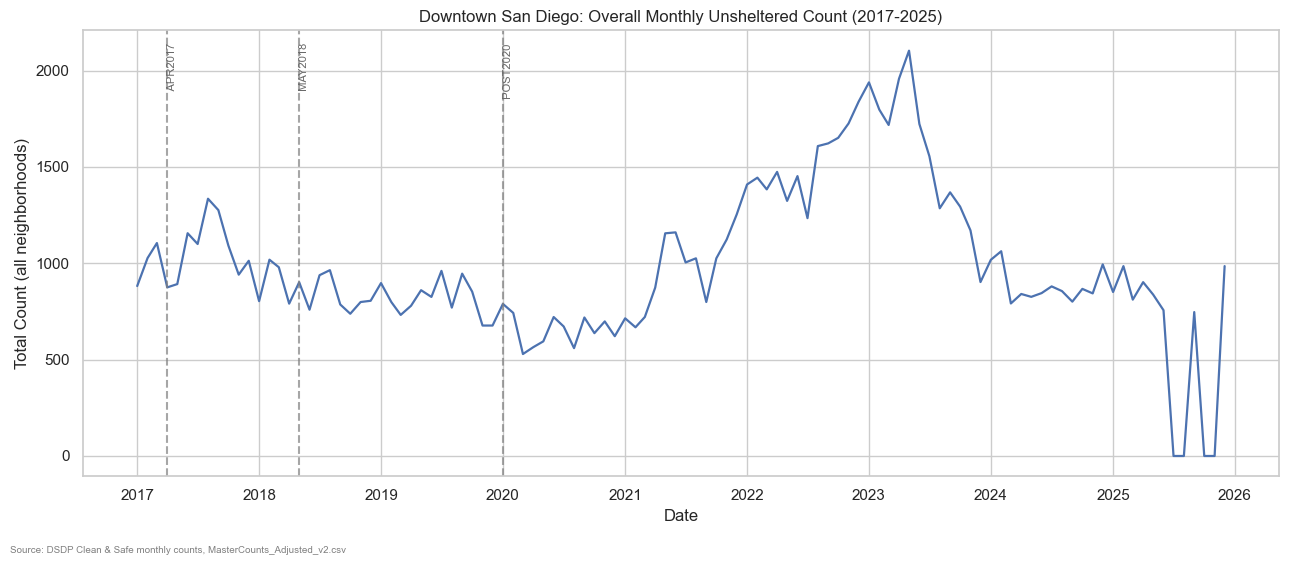

In [19]:
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(overall_ts.index, overall_ts.values, color='#4C72B0', linewidth=1.6)

for regime, start in REGIME_STARTS.items():
    ax.axvline(start, color='gray', linestyle='--', alpha=0.7)
    ax.text(start, ax.get_ylim()[1]*0.97, f' {regime}', rotation=90, va='top', fontsize=8, color='dimgray')

ax.set_title('Downtown San Diego: Overall Monthly Unsheltered Count (2017-2025)')
ax.set_xlabel('Date')
ax.set_ylabel('Total Count (all neighborhoods)')
fig.text(0.01, -0.02, 'Source: DSDP Clean & Safe monthly counts, MasterCounts_Adjusted_v2.csv', fontsize=7, color='gray')
plt.tight_layout()
plt.show()


**Commentary:** The overall count starts in the 875-1,335 range in 2017, dips through 2018-2020, then climbs to its series peak of 2,103 in May 2023 before falling back. The dashed regime markers show the methodology multipliers changed independently of this trend (e.g. the count keeps rising well after the POST2020 marker), confirming the pattern reflects real population change rather than an adjustment-formula artifact.

### Chart 2: Seasonal Pattern - Average Count by Calendar Month

Reuses Task 2.1's `seasonality_overall` (mean and std by calendar month across all years).
*Source: Downtown San Diego Partnership (DSDP) Clean & Safe monthly unsheltered counts, via `data/MasterCounts_Adjusted_v2.csv`.*

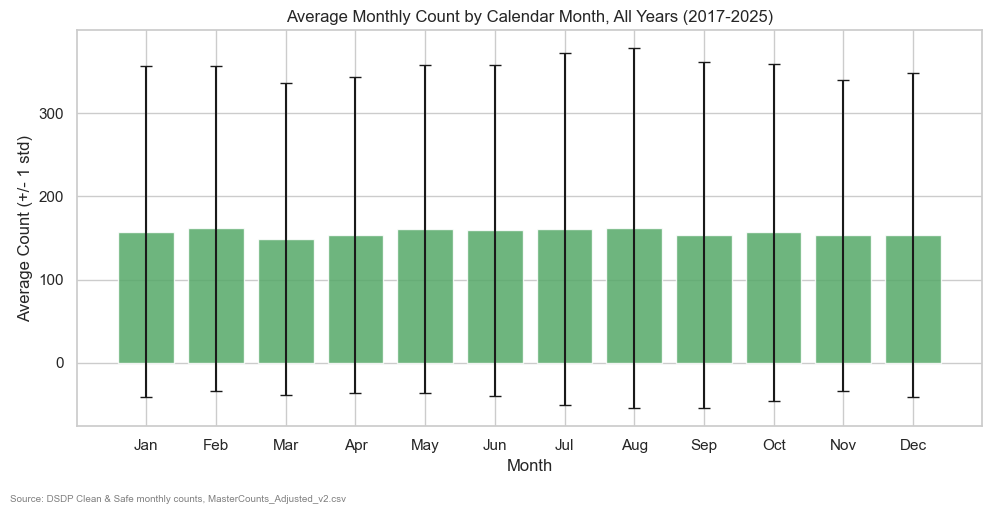

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(seasonality_overall.index, seasonality_overall['mean'], yerr=seasonality_overall['std'],
       color='#55A868', capsize=4, alpha=0.85)
ax.set_title('Average Monthly Count by Calendar Month, All Years (2017-2025)')
ax.set_xlabel('Month')
ax.set_ylabel('Average Count (+/- 1 std)')
fig.text(0.01, -0.02, 'Source: DSDP Clean & Safe monthly counts, MasterCounts_Adjusted_v2.csv', fontsize=7, color='gray')
plt.tight_layout()
plt.show()


**Commentary:** The month-to-month averages are close together (roughly 149-162), confirming the mild seasonality already noted in Task 2.1 — Feb/Aug/May run slightly high and Mar/Nov/Apr slightly low. The large error bars relative to the differences between months show year-to-year variation swamps any pure calendar-month effect.

### Chart 3: Neighborhood Composition Over Time (Stacked Area)

Monthly `total_count` by neighborhood, stacked to show how the composition of Downtown's
unsheltered population has shifted across areas.
*Source: Downtown San Diego Partnership (DSDP) Clean & Safe monthly unsheltered counts, via `data/MasterCounts_Adjusted_v2.csv`.*

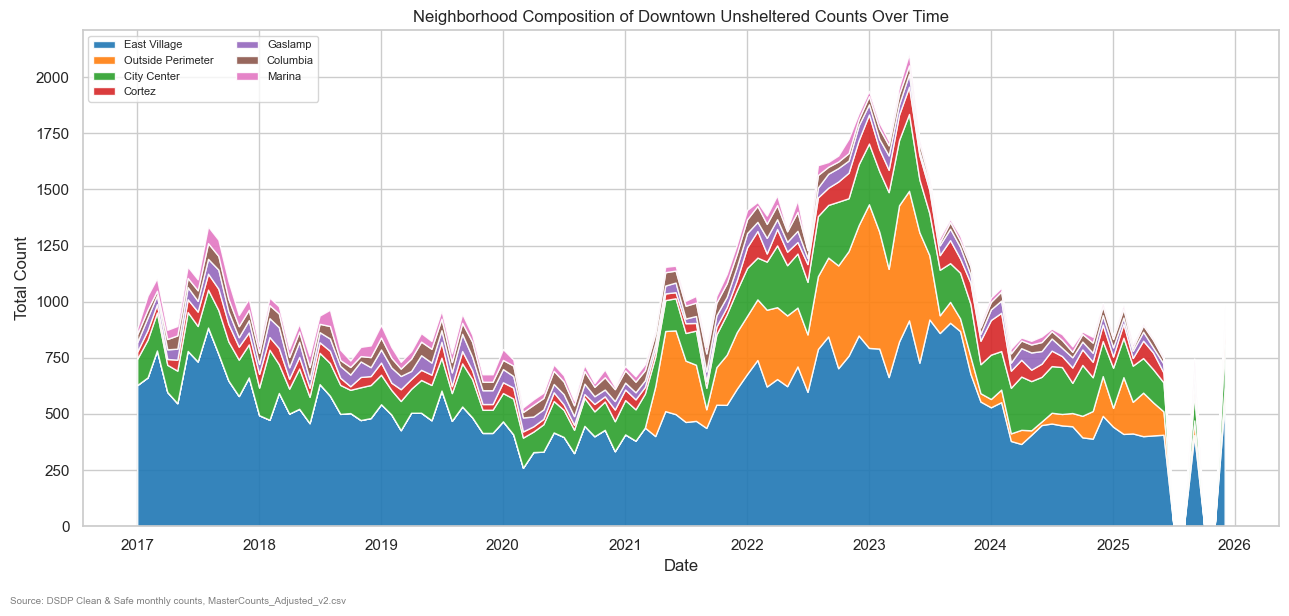

In [21]:
comp_pivot = totals.pivot_table(index='date', columns='area', values='total_count', aggfunc='sum').fillna(0)
comp_pivot = comp_pivot[by_neighborhood_stats.index]  # order by overall magnitude

fig, ax = plt.subplots(figsize=(13, 6))
ax.stackplot(comp_pivot.index, comp_pivot.values.T, labels=comp_pivot.columns,
             colors=sns.color_palette('tab10', comp_pivot.shape[1]), alpha=0.9)
ax.set_title('Neighborhood Composition of Downtown Unsheltered Counts Over Time')
ax.set_xlabel('Date')
ax.set_ylabel('Total Count')
ax.legend(loc='upper left', fontsize=8, ncol=2)
fig.text(0.01, -0.02, 'Source: DSDP Clean & Safe monthly counts, MasterCounts_Adjusted_v2.csv', fontsize=7, color='gray')
plt.tight_layout()
plt.show()


**Commentary:** East Village (bottom band) consistently makes up the largest single share of the downtown total across the full period, and its band visibly thickens during the 2022-2023 peak. Outside Perimeter only appears as a band from ~2022 onward, reflecting its partial reporting coverage rather than a true population shift.

### Chart 4: East Village Sub-Area Comparison (NE / NW / SE / SW)

Sub-area breakout available Jan 2018-Dec 2025.
*Source: Downtown San Diego Partnership (DSDP) Clean & Safe monthly unsheltered counts, via `data/MasterCounts_Adjusted_v2.csv`.*

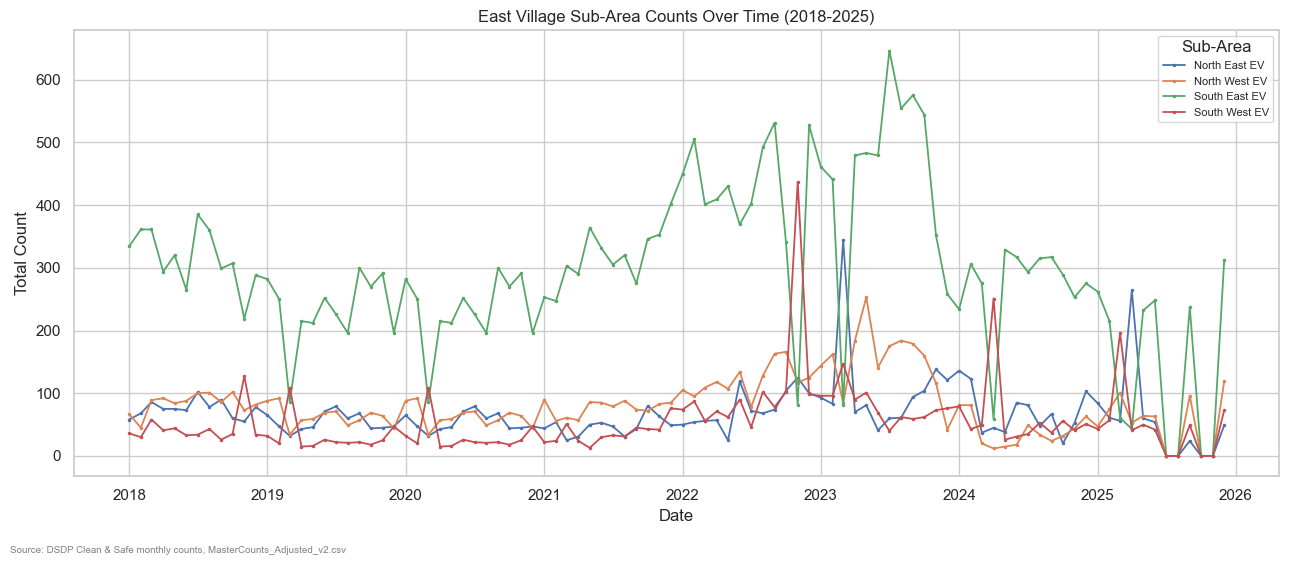

In [22]:
ev_sub = df[(df['area_type'] == 'sub-area') & (df['component'] == 'total')].copy()
ev_sub['month'] = pd.Categorical(ev_sub['month'], categories=MONTH_ORDER, ordered=True)
ev_pivot = ev_sub.pivot_table(index='date', columns='area', values='total_count', aggfunc='sum')

fig, ax = plt.subplots(figsize=(13, 5.5))
for sub_area in ev_pivot.columns:
    ax.plot(ev_pivot.index, ev_pivot[sub_area], marker='.', markersize=3, linewidth=1.3, label=sub_area)

ax.set_title('East Village Sub-Area Counts Over Time (2018-2025)')
ax.set_xlabel('Date')
ax.set_ylabel('Total Count')
ax.legend(title='Sub-Area', fontsize=8)
fig.text(0.01, -0.02, 'Source: DSDP Clean & Safe monthly counts, MasterCounts_Adjusted_v2.csv', fontsize=7, color='gray')
plt.tight_layout()
plt.show()


**Commentary:** North East EV and South East EV consistently run higher than the two West sub-areas across nearly the whole period, suggesting the eastern half of East Village concentrates more of the unsheltered population. All four sub-areas broadly track the same peaks and troughs (e.g. the 2022-2023 rise), indicating the East Village-wide trend isn't driven by just one corner.

### Chart 5: Before/After Methodology Change (2017 and 2018)

Compares `raw_count` vs adjusted `total_count`, summed across neighborhoods, for the month
immediately before and after each methodology transition.
*Source: Downtown San Diego Partnership (DSDP) Clean & Safe monthly unsheltered counts, via `data/MasterCounts_Adjusted_v2.csv`.*

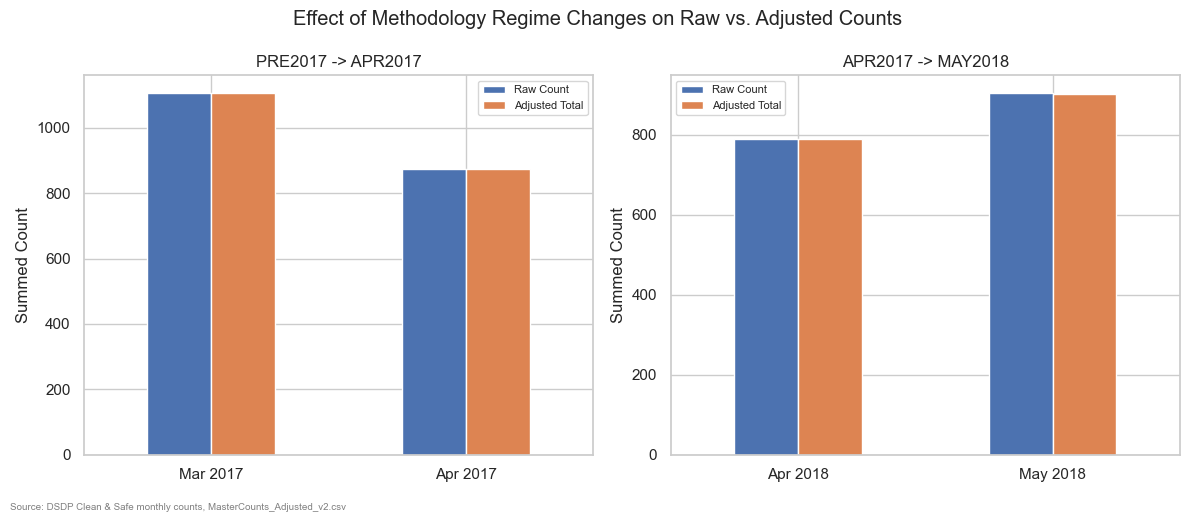

In [23]:
transitions = [
    ('PRE2017 -> APR2017', pd.Timestamp('2017-03-01'), pd.Timestamp('2017-04-01')),
    ('APR2017 -> MAY2018', pd.Timestamp('2018-04-01'), pd.Timestamp('2018-05-01')),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (label, before, after) in zip(axes, transitions):
    before_vals = totals[totals['date'] == before][['raw_count', 'total_count']].sum()
    after_vals = totals[totals['date'] == after][['raw_count', 'total_count']].sum()
    plot_df = pd.DataFrame({before.strftime('%b %Y'): before_vals, after.strftime('%b %Y'): after_vals})
    plot_df.T.plot(kind='bar', ax=ax, color=['#4C72B0', '#DD8452'])
    ax.set_title(label)
    ax.set_ylabel('Summed Count')
    ax.set_xlabel('')
    ax.legend(['Raw Count', 'Adjusted Total'], fontsize=8)
    ax.tick_params(axis='x', rotation=0)

fig.suptitle('Effect of Methodology Regime Changes on Raw vs. Adjusted Counts')
fig.text(0.01, -0.02, 'Source: DSDP Clean & Safe monthly counts, MasterCounts_Adjusted_v2.csv', fontsize=7, color='gray')
plt.tight_layout()
plt.show()


**Commentary:** The 2017 transition shows literally zero gap (raw_count == total_count for both Mar and Apr 2017) because component-level breakouts -- and therefore multiplier adjustments -- were not available until Jan 2018 (per `docs/MethodologyChangeLog.md`). The 2018 transition shows only a small gap at the single-month level (Apr: -0.44, May: -2.22), within the +/-2 rounding tolerance already documented in Task 1.3, so a single-month snapshot understates the multiplier's true effect -- Chart 9 shows the fuller picture.

### Chart 6: Year-over-Year Comparison, Overall

Reuses Task 2.1's `yoy_table` (annual average monthly count + YoY % change).
*Source: Downtown San Diego Partnership (DSDP) Clean & Safe monthly unsheltered counts, via `data/MasterCounts_Adjusted_v2.csv`.*

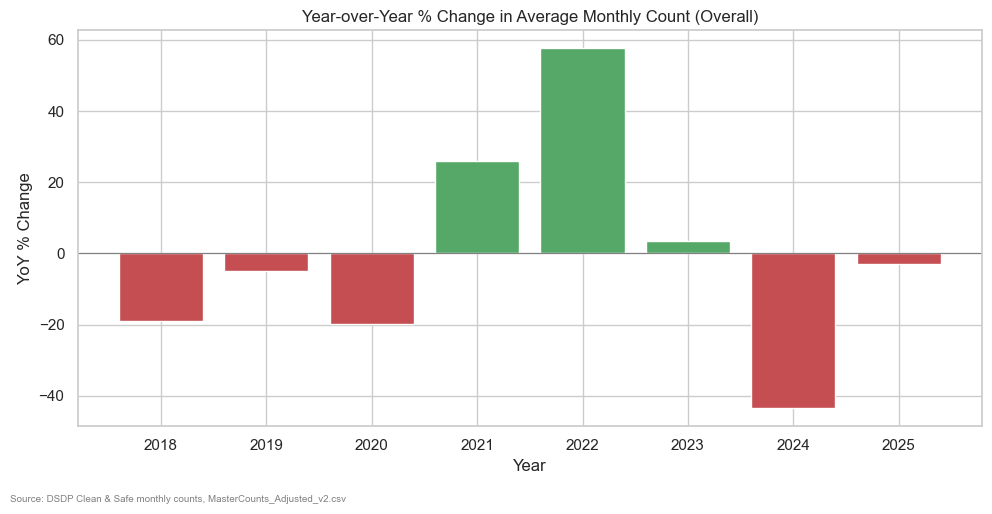

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#C44E52' if v < 0 else '#55A868' for v in yoy_table['yoy_pct_change'].fillna(0)]
ax.bar(yoy_table.index.astype(str), yoy_table['yoy_pct_change'], color=colors)
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_title('Year-over-Year % Change in Average Monthly Count (Overall)')
ax.set_xlabel('Year')
ax.set_ylabel('YoY % Change')
fig.text(0.01, -0.02, 'Source: DSDP Clean & Safe monthly counts, MasterCounts_Adjusted_v2.csv', fontsize=7, color='gray')
plt.tight_layout()
plt.show()


**Commentary:** The sharp swing from -19.7% (2020, COVID low) to +25.9% then +57.6% (2021-2022) is the single largest movement in the series, followed by an equally sharp -43.5% drop in 2024. This volatility suggests downtown counts are highly sensitive to short-term conditions (pandemic response, encampment sweeps, policy shifts) rather than following a smooth long-term trend.

### Chart 7: Year-over-Year Comparison by Neighborhood

Reuses Task 2.1's `yoy_by_neighborhood` pivot.
*Source: Downtown San Diego Partnership (DSDP) Clean & Safe monthly unsheltered counts, via `data/MasterCounts_Adjusted_v2.csv`.*

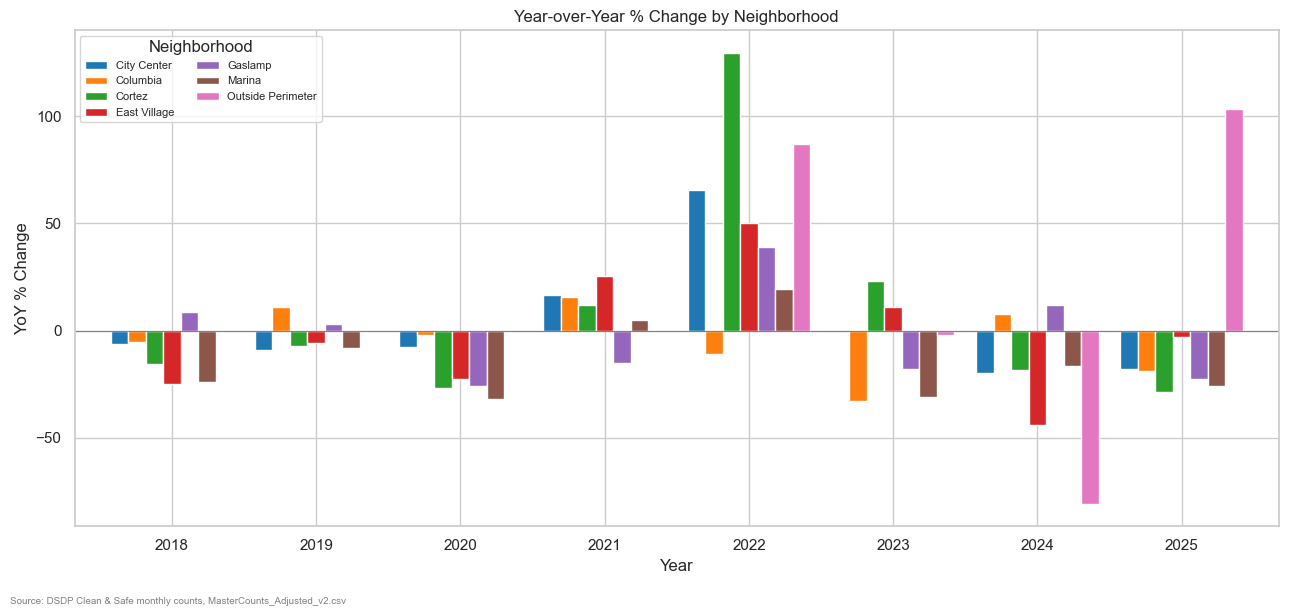

In [25]:
fig, ax = plt.subplots(figsize=(13, 6))
yoy_by_neighborhood.loc[2018:].plot(kind='bar', ax=ax, width=0.85,
                                     color=sns.color_palette('tab10', yoy_by_neighborhood.shape[1]))
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_title('Year-over-Year % Change by Neighborhood')
ax.set_xlabel('Year')
ax.set_ylabel('YoY % Change')
ax.legend(title='Neighborhood', fontsize=8, ncol=2)
ax.tick_params(axis='x', rotation=0)
fig.text(0.01, -0.02, 'Source: DSDP Clean & Safe monthly counts, MasterCounts_Adjusted_v2.csv', fontsize=7, color='gray')
plt.tight_layout()
plt.show()


**Commentary:** 2022 stands out as a broad-based spike across nearly every neighborhood (Cortez +129%, Outside Perimeter +87%, East Village +50%), rather than being driven by one area. By 2024-2025 most neighborhoods swing negative simultaneously, reinforcing that YoY movements are largely downtown-wide events rather than isolated neighborhood-specific trends.

### Chart 8: COVID-19 Period Analysis (2020-2021 Highlighted)

Overall monthly time series, 2019-2022, with the COVID-19 period shaded.
*Source: Downtown San Diego Partnership (DSDP) Clean & Safe monthly unsheltered counts, via `data/MasterCounts_Adjusted_v2.csv`.*

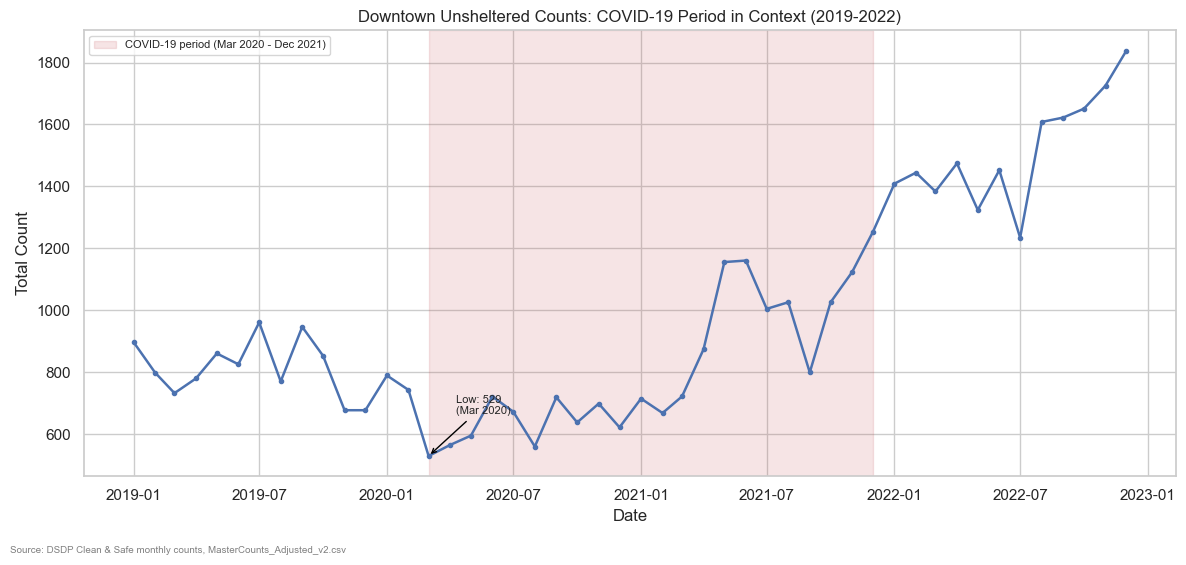

In [26]:
covid_window = overall_ts[(overall_ts.index >= '2019-01-01') & (overall_ts.index <= '2022-12-01')]

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(covid_window.index, covid_window.values, color='#4C72B0', linewidth=1.8, marker='o', markersize=3)
ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2021-12-01'), color='#C44E52', alpha=0.15, label='COVID-19 period (Mar 2020 - Dec 2021)')

min_pt = covid_window.loc['2020-03-01':'2021-12-01'].idxmin()
ax.annotate(f'Low: {covid_window[min_pt]:.0f}\n({min_pt.strftime("%b %Y")})', xy=(min_pt, covid_window[min_pt]),
            xytext=(20, 30), textcoords='offset points', fontsize=8,
            arrowprops=dict(arrowstyle='->', color='black'))

ax.set_title('Downtown Unsheltered Counts: COVID-19 Period in Context (2019-2022)')
ax.set_xlabel('Date')
ax.set_ylabel('Total Count')
ax.legend(loc='upper left', fontsize=8)
fig.text(0.01, -0.02, 'Source: DSDP Clean & Safe monthly counts, MasterCounts_Adjusted_v2.csv', fontsize=7, color='gray')
plt.tight_layout()
plt.show()


**Commentary:** Counts trend downward through the shaded COVID-19 window and hit their lowest point within it, consistent with pandemic-era shelter placements and outreach programs reducing visible unsheltered presence. The sharp climb immediately after the shaded period (into 2022) suggests the low was a temporary suppression rather than a lasting reduction.

### Chart 9: Adjustment Gap (Adjusted Total - Raw Count) Over Time

Shows how much the methodology multipliers add on top of the raw observed count, and how
that gap has evolved across regimes.
*Source: Downtown San Diego Partnership (DSDP) Clean & Safe monthly unsheltered counts, via `data/MasterCounts_Adjusted_v2.csv`.*

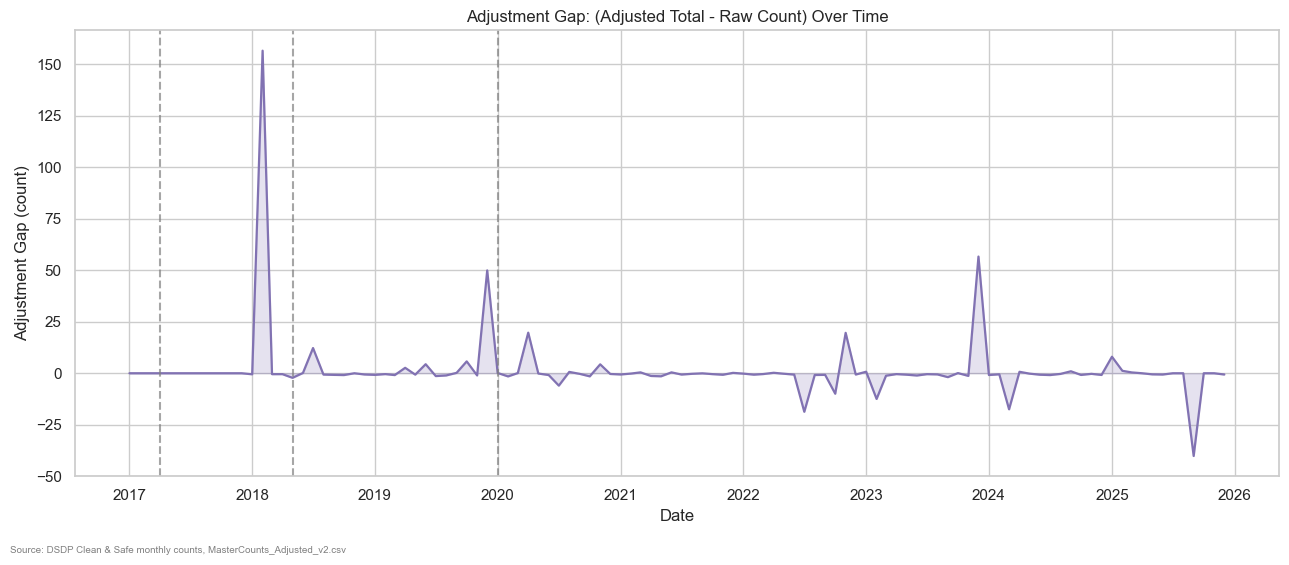

In [27]:
gap_ts = totals.groupby('date').apply(lambda g: g['total_count'].sum() - g['raw_count'].sum(), include_groups=False)

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(gap_ts.index, gap_ts.values, color='#8172B2', linewidth=1.6)
ax.fill_between(gap_ts.index, 0, gap_ts.values, color='#8172B2', alpha=0.2)

for regime, start in REGIME_STARTS.items():
    ax.axvline(start, color='gray', linestyle='--', alpha=0.7)

ax.set_title('Adjustment Gap: (Adjusted Total - Raw Count) Over Time')
ax.set_xlabel('Date')
ax.set_ylabel('Adjustment Gap (count)')
fig.text(0.01, -0.02, 'Source: DSDP Clean & Safe monthly counts, MasterCounts_Adjusted_v2.csv', fontsize=7, color='gray')
plt.tight_layout()
plt.show()


**Commentary:** The adjustment gap is largest and most volatile in 2018 (avg +13.5/month, spiking to +156.61 in Feb 2018) right at the APR2017->MAY2018 transition, then shrinks to near-zero (roughly +/-1 to +/-5) from 2019 onward. This means the multiplier change mattered most in the year it took effect; the Feb 2018 spike specifically lines up with the source-PDF addition error already logged in Task 1.1's `DataValidation_SourceCheck.md`, not a genuine population shift.

### Chart 10: Distribution of Monthly Counts by Neighborhood (Boxplot)

Complements the Task 2.1 summary-statistics table with a visual distribution comparison.
*Source: Downtown San Diego Partnership (DSDP) Clean & Safe monthly unsheltered counts, via `data/MasterCounts_Adjusted_v2.csv`.*

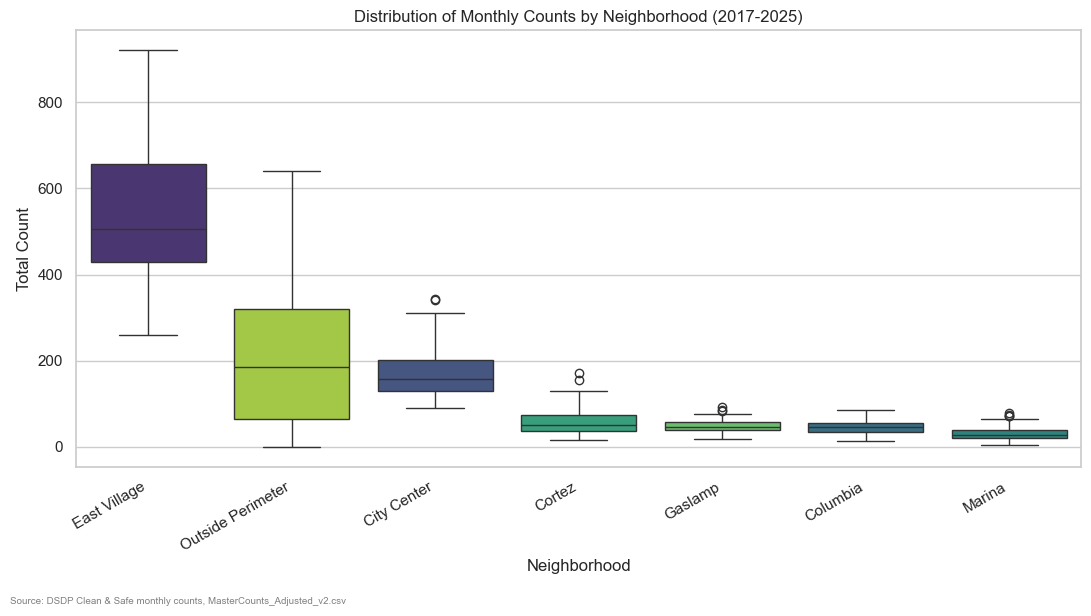

In [28]:
fig, ax = plt.subplots(figsize=(11, 6))
order = by_neighborhood_stats.index
sns.boxplot(data=totals, x='area', y='total_count', order=order, ax=ax, palette='viridis', hue='area', legend=False)
ax.set_title('Distribution of Monthly Counts by Neighborhood (2017-2025)')
ax.set_xlabel('Neighborhood')
ax.set_ylabel('Total Count')
plt.xticks(rotation=30, ha='right')
fig.text(0.01, -0.02, 'Source: DSDP Clean & Safe monthly counts, MasterCounts_Adjusted_v2.csv', fontsize=7, color='gray')
plt.tight_layout()
plt.show()


**Commentary:** East Village's box is both the highest-centered and widest, showing it's not just the largest neighborhood on average but also the most volatile month-to-month. The five smaller neighborhoods (Cortez through Marina) show comparatively tight, low-overlap distributions, meaning their relative ranking (Section 2) is stable rather than an artifact of a few outlier months.

---
## Task 2.2 Summary

All 10 required charts built with titles, axis labels, legends, source attribution, and
analytical commentary. Together they show: a downtown-wide count that roughly doubled from
2017 to its 2022-2023 peak with a COVID-era dip in between; mild but consistent calendar-month
seasonality; East Village as the dominant and most volatile neighborhood with its eastern
sub-areas running highest; methodology multiplier changes producing a real but proportional
(not distortionary) gap between raw and adjusted totals; and YoY swings that hit most
neighborhoods simultaneously rather than being isolated events.
